### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [29]:
data = pd.read_csv('data/coupons.csv')

In [30]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [31]:
# Check the size of the dataset and the type of each column.
print('Dataset shape:', data.shape)

data.info()

# Count exact duplicate rows.
print('Exact duplicate rows:', data.duplicated().sum())

Dataset shape: (12684, 26)
<class 'pandas.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   destination           12684 non-null  str  
 1   passanger             12684 non-null  str  
 2   weather               12684 non-null  str  
 3   temperature           12684 non-null  int64
 4   time                  12684 non-null  str  
 5   coupon                12684 non-null  str  
 6   expiration            12684 non-null  str  
 7   gender                12684 non-null  str  
 8   age                   12684 non-null  str  
 9   maritalStatus         12684 non-null  str  
 10  has_children          12684 non-null  int64
 11  education             12684 non-null  str  
 12  occupation            12684 non-null  str  
 13  income                12684 non-null  str  
 14  car                   108 non-null    str  
 15  Bar                   12577 non-null 

In [32]:
# Check missing values and summary statistics.
print('Missing values by column:')
print(data.isna().sum())

print('Numeric summary:')
print(data.describe())

Missing values by column:
destination                 0
passanger                   0
weather                     0
temperature                 0
time                        0
coupon                      0
expiration                  0
gender                      0
age                         0
maritalStatus               0
has_children                0
education                   0
occupation                  0
income                      0
car                     12576
Bar                       107
CoffeeHouse               217
CarryAway                 151
RestaurantLessThan20      130
Restaurant20To50          189
toCoupon_GEQ5min            0
toCoupon_GEQ15min           0
toCoupon_GEQ25min           0
direction_same              0
direction_opp               0
Y                           0
dtype: int64
Numeric summary:
        temperature  has_children  toCoupon_GEQ5min  toCoupon_GEQ15min  \
count  12684.000000  12684.000000           12684.0       12684.000000   
mean      63.301

3. Decide what to do about your missing data -- drop, replace, other...

In [33]:
# Keep the original data unchanged for reference.
cleaned_data = data.copy()

# Drop car because almost all of its values are missing.
cleaned_data = cleaned_data.drop(columns=['car'])

# Drop this column because every observation has the same value.
cleaned_data = cleaned_data.drop(columns=['toCoupon_GEQ5min'])

# Use snake_case names for easier and more consistent access.
cleaned_data = cleaned_data.rename(columns={
    # Correct the original misspelling for easier navigation.
    'passanger': 'passenger',
    'maritalStatus': 'marital_status',
    'Bar': 'bar',
    'CoffeeHouse': 'coffee_house',
    'CarryAway': 'carry_away',
    'RestaurantLessThan20': 'restaurant_less_than_20',
    'Restaurant20To50': 'restaurant_20_to_50',
    # Spell out that these flags indicate a minimum travel time to the coupon venue.
    'toCoupon_GEQ15min': 'travel_time_to_coupon_at_least_15_min',
    'toCoupon_GEQ25min': 'travel_time_to_coupon_at_least_25_min',
    # Make the outcome clear: 1 means accepted, and 0 means rejected.
    'Y': 'coupon_accepted'
})

cleaned_data.head()

,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,marital_status,...,bar,coffee_house,carry_away,restaurant_less_than_20,restaurant_20_to_50,travel_time_to_coupon_at_least_15_min,travel_time_to_coupon_at_least_25_min,direction_same,direction_opp,coupon_accepted
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,never,NaN,4~8,1~3,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,never,NaN,4~8,1~3,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,never,NaN,4~8,1~3,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,never,NaN,4~8,1~3,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,never,NaN,4~8,1~3,1,0,0,1,0


**Approach**

I followed the early stages of CRISP-DM - understand the problem, explore the data, and decide what to clean before comparing coupon acceptance.

**Cleaning decisions**

The original data is preserved. Based on the data exploration I decided the following:
- Drop the `car` column - this column has mostly missing values and provides limited value.
- Drop the `toCoupon_GEQ5min` column - this column does not provide any variability for analysis.
- Standardize column names - `snake_case` is more natural for column names in Python.
- Rename the `Y` column to `coupon_accepted` - `Y` was pretty cryptic, so I chose a clearer name for the outcome.
- Keep duplicates - I cannot establish whether these are errors, so I decided to retain them.

4. What proportion of the total observations chose to accept the coupon?


In [34]:
# The mean of a 0/1 column is the proportion of accepted coupons.
acceptance_rate = cleaned_data['coupon_accepted'].mean()
print(f'Proportion of coupons accepted: {acceptance_rate:.2%}')

Proportion of coupons accepted: 56.84%


**Acceptance rate**

- Why `.mean()` works - `coupon_accepted` is `1` for accepted and `0` for not accepted. The average is the number of accepted offers divided by the total number of offers.
- Read as a percentage - a mean of about `0.5684` means `56.84%` acceptance.

5. Use a bar plot to visualize the `coupon` column.

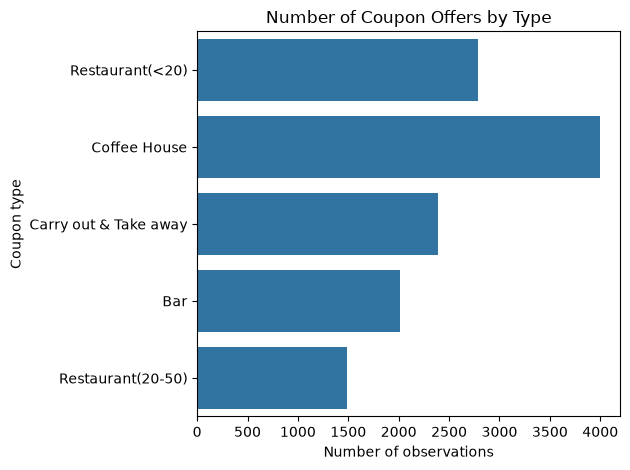

In [35]:
sns.countplot(data=cleaned_data, y='coupon')
plt.title('Number of Coupon Offers by Type')
plt.xlabel('Number of observations')
plt.ylabel('Coupon type')
plt.tight_layout()
plt.show()

6. Use a histogram to visualize the temperature column.

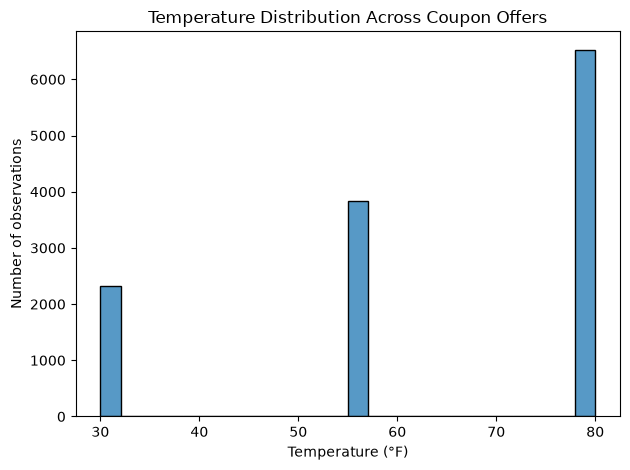

In [36]:
sns.histplot(data=cleaned_data, x='temperature')
plt.title('Temperature Distribution Across Coupon Offers')
plt.xlabel('Temperature (°F)')
plt.ylabel('Number of observations')
plt.tight_layout()
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [37]:
bar_coupons = cleaned_data[cleaned_data['coupon'] == 'Bar'].copy()
bar_coupons.head()

,destination,passenger,weather,temperature,time,coupon,expiration,gender,age,marital_status,...,bar,coffee_house,carry_away,restaurant_less_than_20,restaurant_20_to_50,travel_time_to_coupon_at_least_15_min,travel_time_to_coupon_at_least_25_min,direction_same,direction_opp,coupon_accepted
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,never,NaN,4~8,1~3,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,never,NaN,4~8,1~3,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,never,NaN,4~8,1~3,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,never,less1,4~8,4~8,less1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,never,less1,4~8,4~8,less1,0,0,1,0,1


2. What proportion of bar coupons were accepted?


In [38]:
bar_acceptance_rate = bar_coupons['coupon_accepted'].mean()

print(f'Proportion of bar coupons accepted: {bar_acceptance_rate:.2%}')

Proportion of bar coupons accepted: 41.00%


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [39]:
# Group observations by reported monthly bar visits.
three_or_fewer = bar_coupons[bar_coupons['bar'].isin(['never', 'less1', '1~3'])]
more_than_three = bar_coupons[bar_coupons['bar'].isin(['4~8', 'gt8'])]

print(f"3 or fewer visits: {three_or_fewer['coupon_accepted'].mean():.2%} (n={len(three_or_fewer)})")
print(f"More than 3 visits: {more_than_three['coupon_accepted'].mean():.2%} (n={len(more_than_three)})")

# Missing bar-visit frequency cannot be assigned to either group.
print(f"Missing bar visits: {bar_coupons['bar'].isna().sum()}")

3 or fewer visits: 37.06% (n=1797)
More than 3 visits: 76.88% (n=199)
Missing bar visits: 21


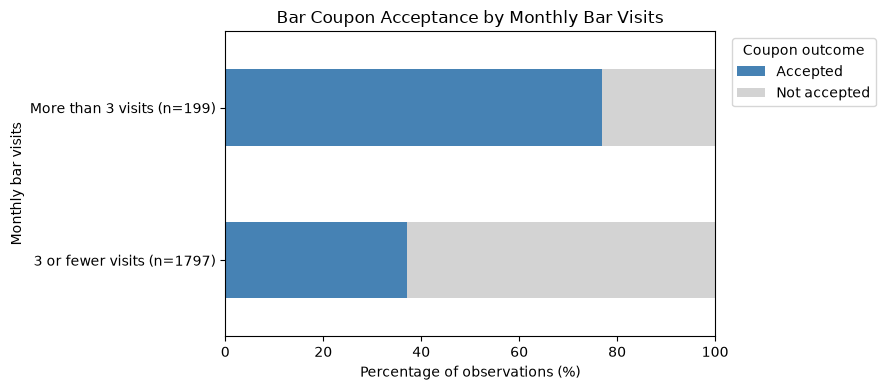

In [40]:
# Each bar shows accepted and not accepted as percentages of its own group.
bar_visit_comparison = pd.DataFrame({
    'Accepted': [
        three_or_fewer['coupon_accepted'].mean() * 100,
        more_than_three['coupon_accepted'].mean() * 100
    ]
}, index=[
    f'3 or fewer visits (n={len(three_or_fewer)})',
    f'More than 3 visits (n={len(more_than_three)})'
])
bar_visit_comparison['Not accepted'] = 100 - bar_visit_comparison['Accepted']
bar_visit_comparison.plot.barh(stacked=True, color=['steelblue', 'lightgray'], figsize=(9, 4))

plt.title('Bar Coupon Acceptance by Monthly Bar Visits')
plt.xlabel('Percentage of observations (%)')
plt.ylabel('Monthly bar visits')
plt.xlim(0, 100)
plt.legend(title='Coupon outcome', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Bar visit comparison**

Based on this comparison I observed the following:
- Higher acceptance among regular bar visitors - `76.88%` accepted among those reporting more than 3 monthly visits (n=199), compared with `37.06%` among those reporting 3 or fewer (n=1,797).
- Compare percentages - the groups have different sizes, so counts alone would not give a fair comparison.
- Exclude missing visit frequency - I cannot assign these `21` observations to either group, so I excluded them rather than counting them as rejected coupons.

**Category limitations**

The survey uses ranges rather than exact values. For the following comparisons I decided the following:
- More than one bar visit - `1~3` includes exactly one visit, so I cannot tell whether these observations meet the condition.
- More than four restaurant visits - `4~8` includes exactly four visits, so I cannot tell whether these observations meet the condition.
- Under 30 - the `26` age category covers ages 26–30, so I cannot separate those under 30 from those who are exactly 30.
- Classify only when possible - I include definite matches and definite non-matches. I leave observations unclassified when ambiguous or missing values prevent group assignment, so some possible matches are excluded. Unclassified refers to group membership, not an unknown coupon outcome.

4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [41]:
# The age categories 26 and above represent ages over 25.
over_25 = bar_coupons['age'].isin(['26', '31', '36', '41', '46', '50plus'])
age_25_or_under = bar_coupons['age'].isin(['below21', '21'])

# 4~8 and gt8 are definitely more than one visit; 1~3 is ambiguous.
more_than_once = bar_coupons['bar'].isin(['4~8', 'gt8'])
at_most_once = bar_coupons['bar'].isin(['never', 'less1'])

frequent_over_25 = bar_coupons[over_25 & more_than_once]
others = bar_coupons[age_25_or_under | (over_25 & at_most_once)]

print(f"More than once and over 25: {frequent_over_25['coupon_accepted'].mean():.2%} (n={len(frequent_over_25)})")
print(f"Other classified observations: {others['coupon_accepted'].mean():.2%} (n={len(others)})")

# Exclude observations whose age or visit frequency cannot determine a group.
excluded = len(bar_coupons) - len(frequent_over_25) - len(others)

print(f'Unclassified observations: {excluded}')

More than once and over 25: 77.21% (n=136)
Other classified observations: 33.42% (n=1577)
Unclassified observations: 304


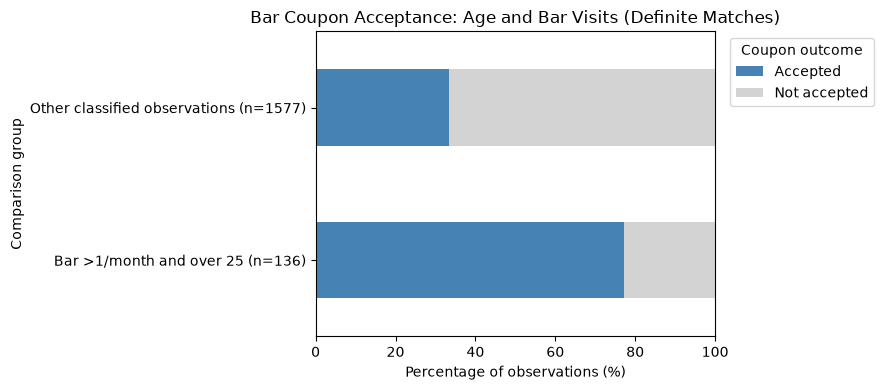

Unclassified observations excluded: 304


In [42]:
age_comparison = pd.DataFrame({
    'Accepted': [frequent_over_25['coupon_accepted'].mean() * 100,
                 others['coupon_accepted'].mean() * 100]
}, index=[f'Bar >1/month and over 25 (n={len(frequent_over_25)})',
          f'Other classified observations (n={len(others)})'])
age_comparison['Not accepted'] = 100 - age_comparison['Accepted']
age_comparison.plot.barh(stacked=True, color=['steelblue', 'lightgray'], figsize=(9, 4))

plt.title('Bar Coupon Acceptance: Age and Bar Visits (Definite Matches)')
plt.xlabel('Percentage of observations (%)')
plt.ylabel('Comparison group')
plt.xlim(0, 100)
plt.legend(title='Coupon outcome', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print(f'Unclassified observations excluded: {excluded}')

**Age and bar visits**

- Higher acceptance in the matching group - `77.21%` accepted among those definitely reporting more than one monthly bar visit and over age 25 (n=136), compared with `33.42%` among other classifiable observations (n=1,577).
- Classification limit - 304 observations remained unclassified. This comparison does not separate age from visit frequency.

5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [43]:
# Only 4~8 and gt8 definitely mean more than one visit per month.
more_than_once = bar_coupons['bar'].isin(['4~8', 'gt8'])
at_most_once = bar_coupons['bar'].isin(['never', 'less1'])

# Not having kids as passengers includes driving alone.
not_kids = bar_coupons['passenger'].isin(['Alone', 'Partner', 'Friend(s)'])
not_farming = bar_coupons['occupation'].notna() & (bar_coupons['occupation'] != 'Farming Fishing & Forestry')
kids_or_farming = (bar_coupons['passenger'] == 'Kid(s)') | (bar_coupons['occupation'] == 'Farming Fishing & Forestry')

matching_observations = bar_coupons[more_than_once & not_kids & not_farming]
other_observations = bar_coupons[at_most_once | kids_or_farming]

print(f"Matching observations: {matching_observations['coupon_accepted'].mean():.2%} (n={len(matching_observations)})")
print(f"Other classified observations: {other_observations['coupon_accepted'].mean():.2%} (n={len(other_observations)})")

# Some observations cannot be classified because visit frequency is ambiguous or missing.
excluded = len(bar_coupons) - len(matching_observations) - len(other_observations)

print(f'Unclassified observations: {excluded}')

Matching observations: 77.49% (n=191)
Other classified observations: 29.49% (n=1448)
Unclassified observations: 378


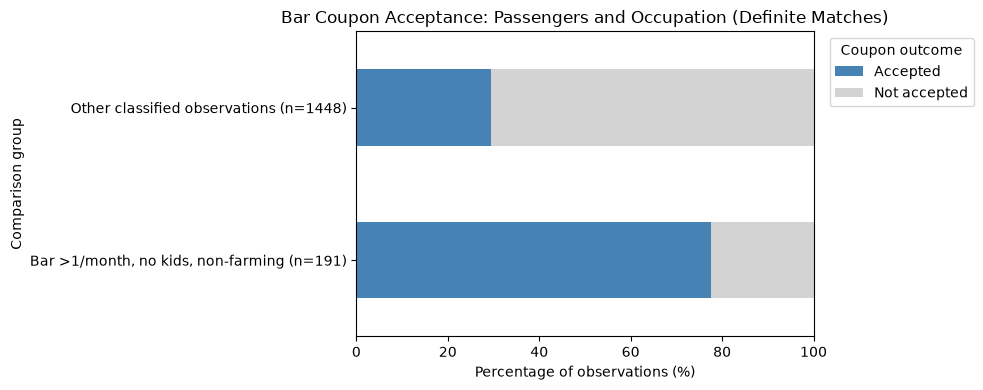

Non-farming excludes Farming Fishing & Forestry.
Unclassified observations excluded: 378


In [44]:
passenger_comparison = pd.DataFrame({
    'Accepted': [matching_observations['coupon_accepted'].mean() * 100,
                 other_observations['coupon_accepted'].mean() * 100]
}, index=[f'Bar >1/month, no kids, non-farming (n={len(matching_observations)})',
          f'Other classified observations (n={len(other_observations)})'])
passenger_comparison['Not accepted'] = 100 - passenger_comparison['Accepted']
passenger_comparison.plot.barh(stacked=True, color=['steelblue', 'lightgray'], figsize=(10, 4))

plt.title('Bar Coupon Acceptance: Passengers and Occupation (Definite Matches)')
plt.xlabel('Percentage of observations (%)')
plt.ylabel('Comparison group')
plt.xlim(0, 100)
plt.legend(title='Coupon outcome', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print('Non-farming excludes Farming Fishing & Forestry.')
print(f'Unclassified observations excluded: {excluded}')

**Passengers, occupation, and bar visits**

- Higher acceptance among definite matches - `77.49%` accepted among observations meeting all three conditions (n=191), compared with `29.49%` among other classifiable observations (n=1,448).
- Combined conditions - 378 observations remained unclassified. The comparison does not show which condition explains the difference.

6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [45]:
# The 1~3 bar category cannot distinguish one visit from more than one.
bar_more_than_once = bar_coupons['bar'].isin(['4~8', 'gt8'])
bar_at_most_once = bar_coupons['bar'].isin(['never', 'less1'])

# Group 1: definitely more than one bar visit, no child passenger, and not widowed.
not_kids = bar_coupons['passenger'].isin(['Alone', 'Partner', 'Friend(s)'])
not_widowed = bar_coupons['marital_status'].notna() & (bar_coupons['marital_status'] != 'Widowed')
group_1 = bar_more_than_once & not_kids & not_widowed
not_group_1 = bar_at_most_once | (bar_coupons['passenger'] == 'Kid(s)') | (bar_coupons['marital_status'] == 'Widowed')

# Group 2: the 26 category spans ages 26–30, so it is ambiguous for under 30.
under_30 = bar_coupons['age'].isin(['below21', '21'])
over_30 = bar_coupons['age'].isin(['31', '36', '41', '46', '50plus'])
group_2 = bar_more_than_once & under_30
not_group_2 = bar_at_most_once | over_30

# Group 3: 4~8 includes exactly four visits, so only gt8 definitely exceeds four.
restaurant_more_than_four = bar_coupons['restaurant_less_than_20'] == 'gt8'
restaurant_at_most_four = bar_coupons['restaurant_less_than_20'].isin(['never', 'less1', '1~3'])
income_under_50k = bar_coupons['income'].isin([
    'Less than $12500', '$12500 - $24999', '$25000 - $37499', '$37500 - $49999'
])
income_50k_or_more = bar_coupons['income'].notna() & ~income_under_50k
group_3 = restaurant_more_than_four & income_under_50k
not_group_3 = restaurant_at_most_four | income_50k_or_more

# Show each group's acceptance rate and how many cases could not be classified.
for label, group, not_group in [
    ('Bar >1/month, no child passenger, not widowed (definite matches)', group_1, not_group_1),
    ('Bar >1/month, age under 30 (definite matches)', group_2, not_group_2),
    ('Cheap restaurant >4/month, income under $50K (definite matches)', group_3, not_group_3),
]:
    matching = bar_coupons[group]
    unclassified = (~(group | not_group)).sum()
    print(f"{label}: {matching['coupon_accepted'].mean():.2%} (n={len(matching)}; unclassified={unclassified})")

# OR combines the groups without counting an observation twice.
any_group = group_1 | group_2 | group_3
no_group = not_group_1 & not_group_2 & not_group_3
matching_any = bar_coupons[any_group]

print(f"Any group: {matching_any['coupon_accepted'].mean():.2%} (n={len(matching_any)}; unclassified={(~(any_group | no_group)).sum()})")

Bar >1/month, no child passenger, not widowed (definite matches): 77.49% (n=191; unclassified=378)
Bar >1/month, age under 30 (definite matches): 76.19% (n=63; unclassified=286)
Cheap restaurant >4/month, income under $50K (definite matches): 59.38% (n=96; unclassified=262)
Any group: 70.85% (n=271; unclassified=531)


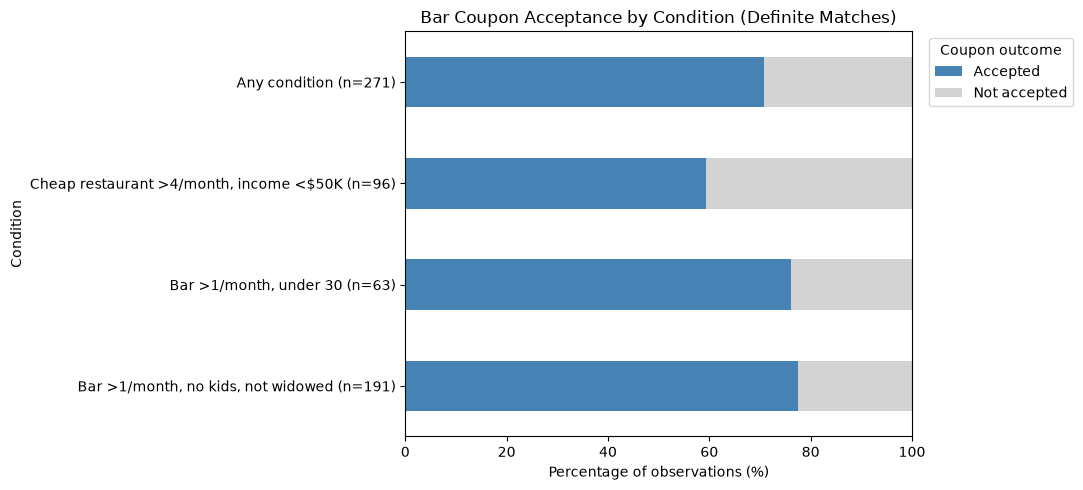

Groups overlap. Unclassified counts are reported in the preceding cell.


In [46]:
# Groups overlap; the combined OR group counts each observation once.
condition_comparison = pd.DataFrame({
    'Accepted': [
        bar_coupons[group_1]['coupon_accepted'].mean() * 100,
        bar_coupons[group_2]['coupon_accepted'].mean() * 100,
        bar_coupons[group_3]['coupon_accepted'].mean() * 100,
        matching_any['coupon_accepted'].mean() * 100
    ]
}, index=[
    f'Bar >1/month, no kids, not widowed (n={group_1.sum()})',
    f'Bar >1/month, under 30 (n={group_2.sum()})',
    f'Cheap restaurant >4/month, income <$50K (n={group_3.sum()})',
    f'Any condition (n={any_group.sum()})'
])
condition_comparison['Not accepted'] = 100 - condition_comparison['Accepted']
condition_comparison.plot.barh(stacked=True, color=['steelblue', 'lightgray'], figsize=(11, 5))

plt.title('Bar Coupon Acceptance by Condition (Definite Matches)')
plt.xlabel('Percentage of observations (%)')
plt.ylabel('Condition')
plt.xlim(0, 100)
plt.legend(title='Coupon outcome', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print('Groups overlap. Unclassified counts are reported in the preceding cell.')

**Combined conditions**

- Higher acceptance in the two bar-visit groups - acceptance was `77.49%` (n=191) and `76.19%` (n=63), compared with `59.38%` in the restaurant-visit and income group (n=96).
- Overlapping groups - the combined OR group had `70.85%` acceptance across 271 observations, counting each observation once. Another 531 observations remained unclassified.

7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

Based on these comparisons I hypothesize that bar coupon acceptance is higher among observations with regular bar visits. However, this does not mean that visiting bars more often causes higher acceptance. The data describes responses to hypothetical scenarios, so it does not show actual coupon use.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

**Coffee-house investigation**

I wanted to see whether the visit-frequency pattern from the bar investigation also appears for coffee-house coupons. I chose the following columns based on these ideas:
- Coffee-house visit frequency - acceptance may be higher among observations with reported coffee-house visits.
- Travel time - acceptance may be higher among observations with shorter travel times.
- Temperature - acceptance may differ between colder and warmer scenarios.
- Weather - rain or snow may make a trip less appealing than sunny weather.

I will compare acceptance percentages and group sizes to see whether the results support these ideas. The data gives travel time, not exact driving distance.

In [47]:
# Select coffee-house coupon offers. The coffee_house column records visit frequency.
coffee_coupons = cleaned_data[cleaned_data['coupon'] == 'Coffee House'].copy()

print(f'Coffee-house coupon observations: {len(coffee_coupons):,}')
print(f"Overall acceptance rate: {coffee_coupons['coupon_accepted'].mean():.2%}")

Coffee-house coupon observations: 3,996
Overall acceptance rate: 49.92%


In [48]:
# Keep the original visit ranges because exact visit counts are unknown.
visit_order = ['never', 'less1', '1~3', '4~8', 'gt8']
visit_comparison = coffee_coupons.groupby('coffee_house')['coupon_accepted'].agg(['count', 'mean'])
visit_comparison = visit_comparison.reindex(visit_order)
visit_comparison = visit_comparison.rename(columns={'count': 'Observations', 'mean': 'Accepted (%)'})
visit_comparison['Accepted (%)'] = visit_comparison['Accepted (%)'] * 100
visit_comparison.index = ['Never', 'Less than once', '1–3 visits', '4–8 visits', 'More than 8 visits']
print('Acceptance by reported monthly coffee-house visits:')
print(visit_comparison.round(2))

# Exclude missing visit frequency from this comparison only.
print(f"Missing coffee-house visit frequency excluded: {coffee_coupons['coffee_house'].isna().sum()}")

Acceptance by reported monthly coffee-house visits:
                    Observations  Accepted (%)
Never                        927         18.88
Less than once              1075         48.19
1–3 visits                  1042         64.78
4–8 visits                   538         68.59
More than 8 visits           342         65.79
Missing coffee-house visit frequency excluded: 72


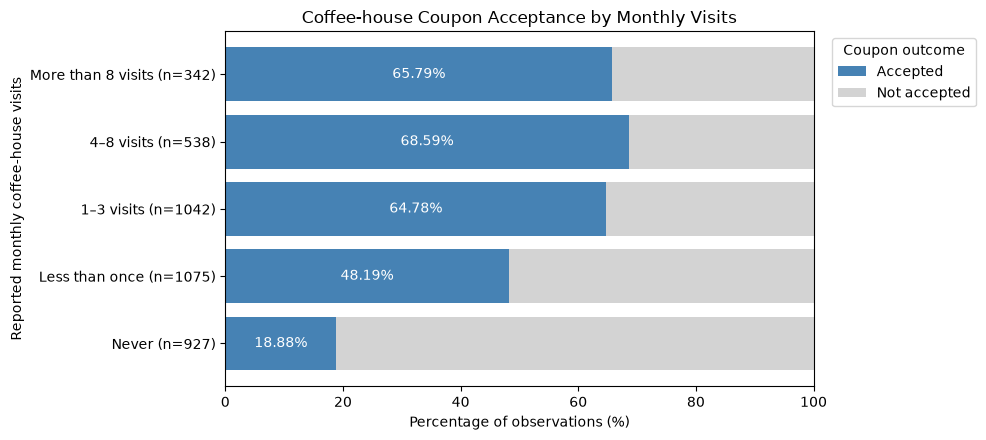

In [49]:
# Use percentages because the visit groups have different sizes.
visit_outcomes = pd.DataFrame({'Accepted': visit_comparison['Accepted (%)']})
visit_outcomes['Not accepted'] = 100 - visit_outcomes['Accepted']
visit_labels = visit_comparison.index + ' (n=' + visit_comparison['Observations'].astype(str) + ')'

plt.figure(figsize=(10, 4.5))
accepted_bars = plt.barh(visit_labels, visit_outcomes['Accepted'], color='steelblue', label='Accepted')
plt.barh(visit_labels, visit_outcomes['Not accepted'], left=visit_outcomes['Accepted'], color='lightgray', label='Not accepted')
plt.bar_label(accepted_bars, fmt='%.2f%%', label_type='center', color='white')
plt.title('Coffee-house Coupon Acceptance by Monthly Visits')
plt.xlabel('Percentage of observations (%)')
plt.ylabel('Reported monthly coffee-house visits')
plt.xlim(0, 100)
plt.legend(title='Coupon outcome', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

# Save this figure so the README shows the same results as the notebook.
plt.savefig('images/coffee-house-acceptance.png', dpi=160, bbox_inches='tight')
plt.show()

**Coffee-house visit comparison**

- Higher acceptance among coffee-house visitors - `18.88%` accepted among those who reported never visiting (n=927), compared with `48.19%` for less than once a month (n=1,075) and `64.78%` for 1–3 visits (n=1,042).
- More visits did not always mean higher acceptance - `68.59%` accepted for 4–8 visits (n=538), compared with `65.79%` for more than 8 visits (n=342).
- Exclude missing frequency - I cannot assign 72 observations to a visit group, so I left them out of this comparison. I kept them for the other comparisons.

In [50]:
# Check the two travel-time flags before creating separate groups.
print('Travel-time flag combinations:')
print(coffee_coupons.groupby([
    'travel_time_to_coupon_at_least_15_min',
    'travel_time_to_coupon_at_least_25_min'
]).size())

# Assign each offer to one group using the 15- and 25-minute cutoffs.
coffee_coupons['travel_time'] = 'Under 15 min'
coffee_coupons.loc[coffee_coupons['travel_time_to_coupon_at_least_15_min'] == 1, 'travel_time'] = '15 to under 25 min'
coffee_coupons.loc[coffee_coupons['travel_time_to_coupon_at_least_25_min'] == 1, 'travel_time'] = '25 min or more'

travel_order = ['Under 15 min', '15 to under 25 min', '25 min or more']
travel_comparison = coffee_coupons.groupby('travel_time')['coupon_accepted'].agg(['count', 'mean'])
travel_comparison = travel_comparison.reindex(travel_order)
travel_comparison = travel_comparison.rename(columns={'count': 'Observations', 'mean': 'Accepted (%)'})
travel_comparison['Accepted (%)'] = travel_comparison['Accepted (%)'] * 100
print('\nAcceptance by travel time:')
print(travel_comparison.round(2))

Travel-time flag combinations:
travel_time_to_coupon_at_least_15_min  travel_time_to_coupon_at_least_25_min
0                                      0                                        1923
1                                      0                                        1763
                                       1                                         310
dtype: int64

Acceptance by travel time:
                    Observations  Accepted (%)
travel_time                                   
Under 15 min                1923         54.81
15 to under 25 min          1763         47.31
25 min or more               310         34.52


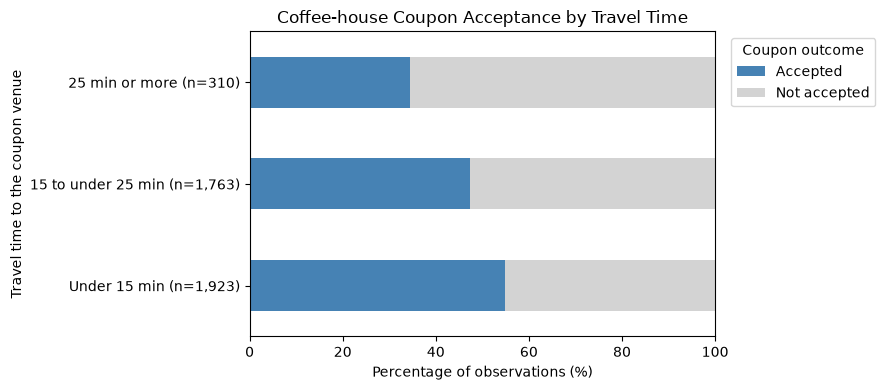

In [51]:
# Show accepted and not accepted as percentages of each travel-time group.
travel_outcomes = pd.DataFrame({
    'Accepted': travel_comparison['Accepted (%)'],
    'Not accepted': 100 - travel_comparison['Accepted (%)']
})
travel_outcomes.index = [
    f"Under 15 min (n={travel_comparison.loc['Under 15 min', 'Observations']:,})",
    f"15 to under 25 min (n={travel_comparison.loc['15 to under 25 min', 'Observations']:,})",
    f"25 min or more (n={travel_comparison.loc['25 min or more', 'Observations']:,})"
]
travel_outcomes.plot.barh(stacked=True, color=['steelblue', 'lightgray'], figsize=(9, 4))
plt.title('Coffee-house Coupon Acceptance by Travel Time')
plt.xlabel('Percentage of observations (%)')
plt.ylabel('Travel time to the coupon venue')
plt.xlim(0, 100)
plt.legend(title='Coupon outcome', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Travel-time comparison**

- Lower acceptance for longer trips - `54.81%` accepted for trips under 15 minutes (n=1,923), `47.31%` for trips from 15 to under 25 minutes (n=1,763), and `34.52%` for trips of at least 25 minutes (n=310).
- Matches my expectation - the shortest and longest travel-time groups differ by 20.29 percentage points. However, the comparison does not show whether travel time alone explains the difference.

In [52]:
# Count the observations and calculate acceptance percentages for each group.
temperature_comparison = coffee_coupons.groupby('temperature')['coupon_accepted'].agg(['count', 'mean'])
temperature_comparison = temperature_comparison.rename(columns={'count': 'Observations', 'mean': 'Accepted (%)'})
temperature_comparison['Accepted (%)'] = temperature_comparison['Accepted (%)'] * 100

weather_comparison = coffee_coupons.groupby('weather')['coupon_accepted'].agg(['count', 'mean'])
weather_comparison = weather_comparison.rename(columns={'count': 'Observations', 'mean': 'Accepted (%)'})
weather_comparison['Accepted (%)'] = weather_comparison['Accepted (%)'] * 100

print('Acceptance by temperature:')
print(temperature_comparison.round(2))
print('\nAcceptance by weather:')
print(weather_comparison.round(2))

Acceptance by temperature:
             Observations  Accepted (%)
temperature                            
30                    318         44.34
55                   1277         45.58
80                   2401         52.98

Acceptance by weather:
         Observations  Accepted (%)
weather                            
Rainy             226         52.21
Snowy             303         43.23
Sunny            3467         50.36


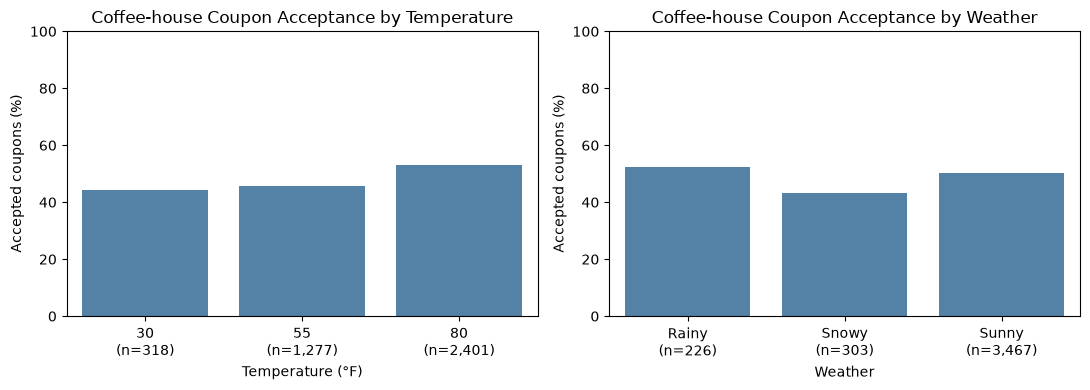

In [53]:
# Keep both plots on the same 0–100% scale for comparison.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=temperature_comparison.reset_index(), x='temperature', y='Accepted (%)', color='steelblue', ax=axes[0])
axes[0].set_title('Coffee-house Coupon Acceptance by Temperature')
axes[0].set_xlabel('Temperature (°F)')
axes[0].set_xticks(range(len(temperature_comparison)), labels=[
    f'{temperature}\n(n={count:,})'
    for temperature, count in temperature_comparison['Observations'].items()
])
axes[0].set_ylabel('Accepted coupons (%)')
axes[0].set_ylim(0, 100)

sns.barplot(data=weather_comparison.reset_index(), x='weather', y='Accepted (%)', color='steelblue', ax=axes[1])
axes[1].set_title('Coffee-house Coupon Acceptance by Weather')
axes[1].set_xlabel('Weather')
axes[1].set_xticks(range(len(weather_comparison)), labels=[
    f'{weather}\n(n={count:,})'
    for weather, count in weather_comparison['Observations'].items()
])
axes[1].set_ylabel('Accepted coupons (%)')
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.show()

**Temperature and weather comparison**

- Higher acceptance at 80°F - `52.98%` accepted, compared with `45.58%` at 55°F and `44.34%` at 30°F. This does not show that warmer weather caused higher acceptance.
- Weather did not fully match my expectation - acceptance was lower in snow (`43.23%`) than sunshine (`50.36%`), but higher in rain (`52.21%`).
- Different group sizes - there were 3,467 sunny offers, but only 226 rainy and 303 snowy offers. I would be careful about generalizing from the smaller groups.

In [54]:
# Check which temperatures appear with each type of weather.
print('Observations by temperature and weather:')
print(pd.crosstab(coffee_coupons['temperature'], coffee_coupons['weather']))

Observations by temperature and weather:
weather      Rainy  Snowy  Sunny
temperature                     
30               0    303     15
55             226      0   1051
80               0      0   2401


**Temperature and weather limitation**

- Temperature and weather overlap - all rainy offers were at 55°F and all snowy offers were at 30°F. These comparisons do not show which of the two explains the acceptance differences.

**Coffee-house findings**

Based on these comparisons I observed the following:
- Coffee-house visits - acceptance was higher among observations with reported coffee-house visits than among those with no visits. This matches my expectation, although more visits did not always mean higher acceptance.
- Travel time - acceptance was lower for longer trips, which also matches my expectation.
- Temperature and weather - acceptance differed, but these comparisons do not separate the two patterns.
- Keep the limits in mind - these are hypothetical responses, so they do not establish actual coupon use. Observations may come from the same respondent, and I kept exact duplicates because I cannot establish whether they are errors. The results show associations, not causes.

**Recommendations**

- Start with a small test - I would test nearby coffee-house offers among reported visitors, based on their higher acceptance in the separate comparisons.
- Avoid weather-only decisions - temperature and weather overlap, so I would not use either factor alone to decide who receives an offer.

**Next steps**

- Check the combination - I looked at visits and travel time separately. Next I would compare visit frequency within each travel-time group and report group sizes and missing values.
- Time of day - coffee may fit a morning routine, so morning offers may have higher acceptance. I would compare 7AM and 10AM separately with later offers.
- Coupon expiration - a 2-hour limit may leave too little time to use an offer. I would compare acceptance for 2-hour and 24-hour offers.